# 03 — Exploratory Data Analysis (EDA)

This notebook looks for patterns in late delivery. Run `02_clean.ipynb` first so `orders_clean.csv` exists.

Charts are descriptive: a relationship between a feature and late delivery does not automatically mean that the feature causes delays.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / "data/processed/orders_clean.csv",
                 parse_dates=["order_purchase_timestamp",
                              "order_delivered_customer_date",
                              "order_estimated_delivery_date"])
sns.set_theme()
print("Shape:", df.shape)
display(df.head())

Shape: (96470, 24)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_price,total_freight,...,payment_installments,payment_type,customer_state,customer_lat,customer_lng,seller_state,seller_lat,seller_lng,product_category_name,late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,29.99,8.72,...,1.0,credit_card,SP,-23.576983,-46.587161,SP,-23.680729,-46.444238,utilidades_domesticas,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,118.70,22.76,...,1.0,boleto,BA,-12.177924,-44.660711,SP,-19.807681,-43.980427,perfumaria,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,159.90,19.22,...,3.0,credit_card,GO,-16.745150,-48.514783,SP,-21.363502,-48.229601,automotivo,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,45.00,27.20,...,1.0,credit_card,RN,-5.774190,-35.271143,MG,-19.837682,-43.924053,pet_shop,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,19.90,8.72,...,1.0,credit_card,SP,-23.676370,-46.514627,SP,-23.543395,-46.262086,papelaria,0


## 1. Target distribution

,orders,percentage
late,,
Not late,88644,91.89
Late,7826,8.11


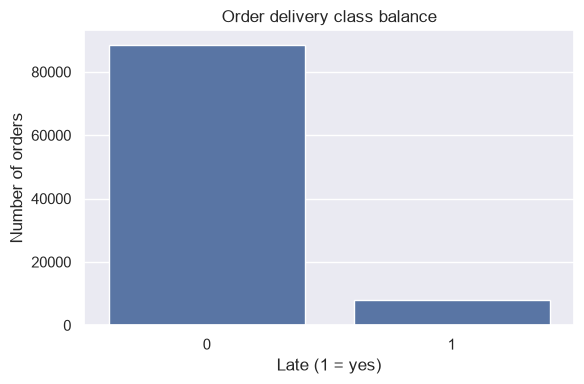

In [2]:
target_counts = df["late"].value_counts().sort_index()
display(pd.DataFrame({
    "orders": target_counts,
    "percentage": (target_counts / len(df) * 100).round(2)
}).rename(index={0: "Not late", 1: "Late"}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="late")
plt.title("Order delivery class balance")
plt.xlabel("Late (1 = yes)")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

## 2. Numerical feature distributions

,count,mean,std,min,25%,50%,75%,max
total_price,96470.0,137.040001,209.052608,0.85,45.90,86.50,149.90,13440.00
total_freight,96470.0,22.785798,21.559959,0.00,13.85,17.17,24.02,1794.96
item_count,96470.0,1.142210,0.538824,1.00,1.00,1.00,1.00,21.00
payment_value,96469.0,159.855320,218.820934,9.59,61.88,105.28,176.33,13664.08


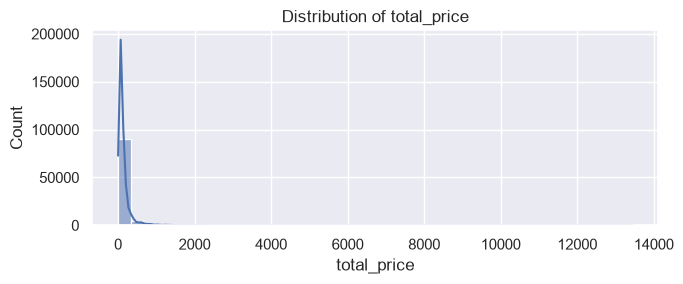

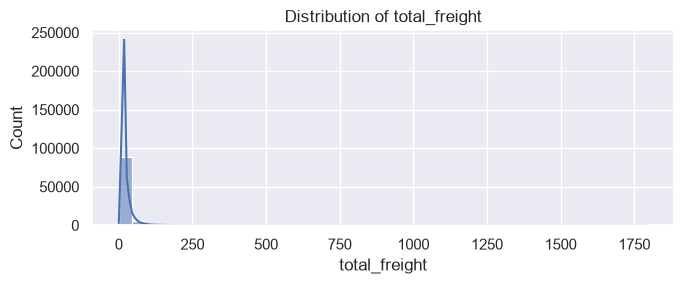

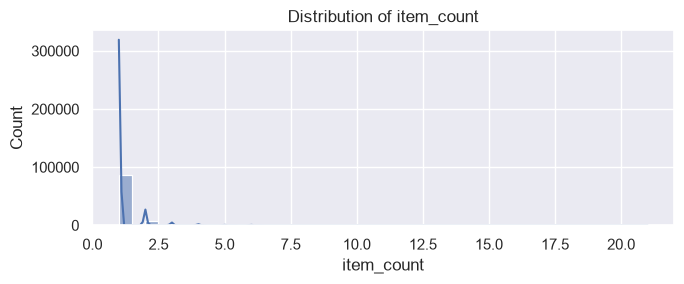

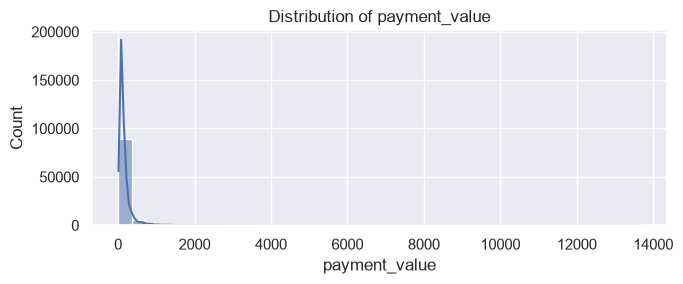

In [3]:
numeric_cols = ["total_price", "total_freight", "item_count", "payment_value"]
display(df[numeric_cols].describe().T)

for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.histplot(df[col].dropna(), bins=40, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

## 3. Delivery delay in days

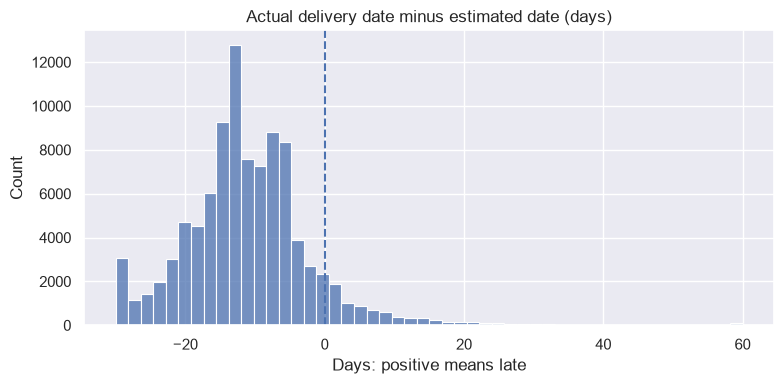

In [4]:
df["delivery_difference_days"] = (
    df["order_delivered_customer_date"] -
    df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

plt.figure(figsize=(8, 4))
sns.histplot(df["delivery_difference_days"].clip(-30, 60), bins=50)
plt.axvline(0, linestyle="--")
plt.title("Actual delivery date minus estimated date (days)")
plt.xlabel("Days: positive means late")
plt.tight_layout()
plt.show()

## 4. Late rate by product category

,orders,late_rate
product_category_name,,
audio,344,13.1%
fashion_underwear_e_moda_praia,117,12.8%
livros_tecnicos,255,11.0%
casa_conforto,370,10.3%
alimentos,435,10.1%
eletronicos,2507,9.9%
artigos_de_natal,125,9.6%
bebes,2763,9.3%
moveis_escritorio,1246,9.2%


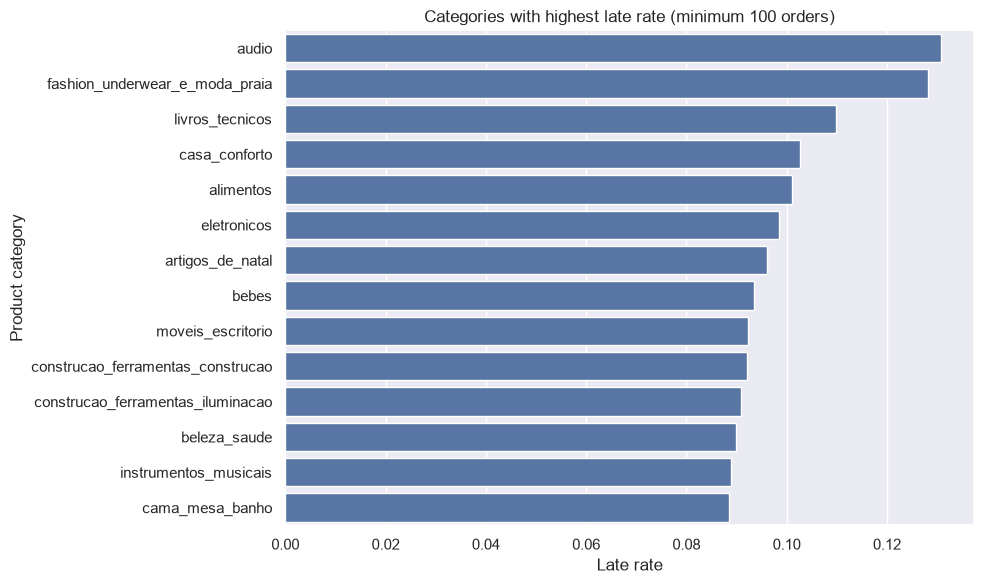

In [5]:
category_stats = (df.groupby("product_category_name", dropna=False)
    .agg(orders=("late", "size"), late_rate=("late", "mean"))
    .query("orders >= 100")
    .sort_values("late_rate", ascending=False)
    .head(15))
display(category_stats.style.format({"late_rate": "{:.1%}"}))

plt.figure(figsize=(10, 6))
sns.barplot(data=category_stats.reset_index(),
            y="product_category_name", x="late_rate")
plt.title("Categories with highest late rate (minimum 100 orders)")
plt.xlabel("Late rate")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

## 5. Approximate seller-to-customer distance

,mean,count
distance_band,,
0–100,6.4%,17904
100–300,6.4%,13336
300–600,7.7%,31491
600–1000,8.5%,17904
1000+,11.8%,15219


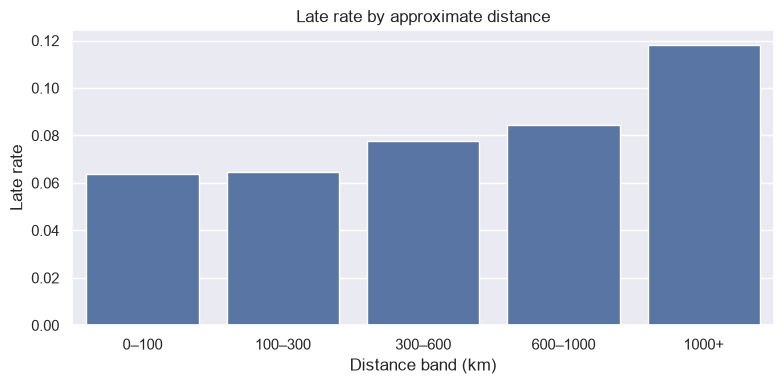

In [6]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = [np.radians(v) for v in (lat1, lon1, lat2, lon2)]
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine_km(
    df["seller_lat"], df["seller_lng"],
    df["customer_lat"], df["customer_lng"]
)
df["distance_band"] = pd.cut(
    df["distance_km"], [-1, 100, 300, 600, 1000, 3000],
    labels=["0–100", "100–300", "300–600", "600–1000", "1000+"]
)
distance_stats = df.groupby("distance_band", observed=False)["late"].agg(["mean", "count"])
display(distance_stats.style.format({"mean": "{:.1%}"}))

plt.figure(figsize=(8, 4))
sns.barplot(x=distance_stats.index.astype(str), y=distance_stats["mean"])
plt.title("Late rate by approximate distance")
plt.xlabel("Distance band (km)")
plt.ylabel("Late rate")
plt.tight_layout()
plt.show()

## 6. Purchase timing

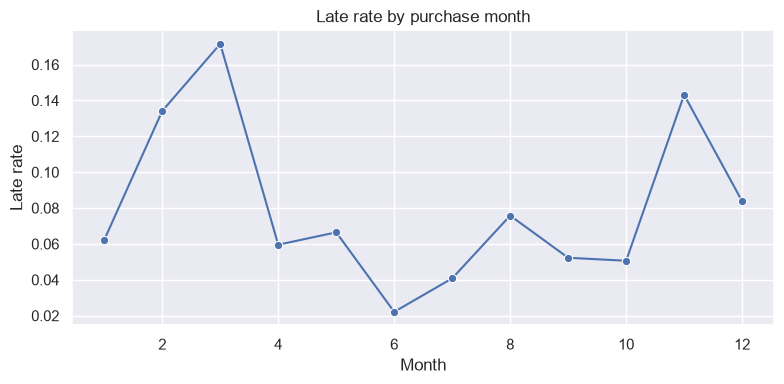

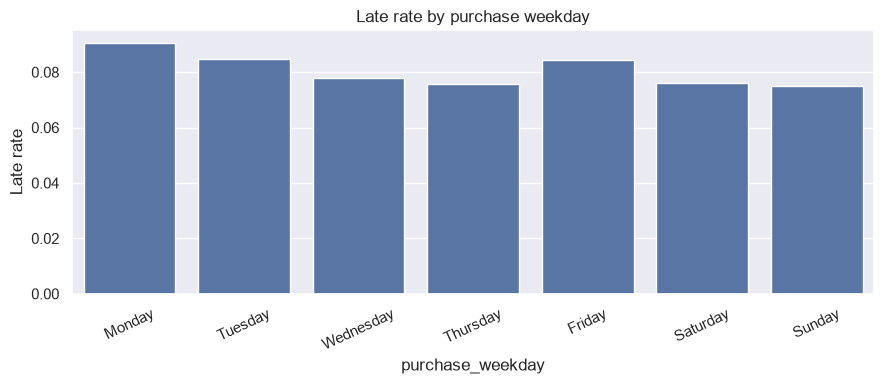

In [7]:
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.day_name()

month_stats = df.groupby("purchase_month")["late"].mean()
plt.figure(figsize=(8, 4))
sns.lineplot(x=month_stats.index, y=month_stats.values, marker="o")
plt.title("Late rate by purchase month")
plt.xlabel("Month")
plt.ylabel("Late rate")
plt.tight_layout()
plt.show()

weekday_stats = df.groupby("purchase_weekday")["late"].mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)
plt.figure(figsize=(9, 4))
sns.barplot(x=weekday_stats.index, y=weekday_stats.values)
plt.xticks(rotation=25)
plt.title("Late rate by purchase weekday")
plt.ylabel("Late rate")
plt.tight_layout()
plt.show()

## 7. Findings — complete after running

Write 3–5 findings based on the actual charts above.

1. **Finding:**  
   **Evidence:**  
   **Possible business meaning:**  

2. **Finding:**  
   **Evidence:**  
   **Possible business meaning:**  

3. **Finding:**  
   **Evidence:**  
   **Possible business meaning:**  

4. **Data limitation:**  

5. **Hypothesis worth testing:**  

Do not write results before you have run the notebook and seen the numbers.